# 4. What would I recommend to the support lead?

First apply the planned decision rule. Then use segment results to identify what to investigate, without turning exploratory results into a new success criterion.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / 'config').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
from support_policy.common import config
mart = pl.read_parquet(ROOT / 'data/marts/experiment_mart.parquet')
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.spines.top': False, 'axes.spines.right': False})
pl.Config.set_tbl_rows(20)
print(f'{mart.height:,} customers; synthetic data only')


100,000 customers; synthetic data only


## Apply the original gate

In [2]:
from support_policy.rollout_scenarios import decision,scenario
health=json.loads((ROOT/'outputs/experiment_checks.json').read_text())
effects=pl.read_csv(ROOT/'outputs/tables/treatment_effects.csv')
verdict=decision(effects,health)
display(verdict)


{'recommendation': 'Revise and retest',
 'primary_pass': True,
 'failed_guardrails': ['repeat_contact_7d'],
 'missing_results': [],
 'primary_target_hours': 2.0,
 'guardrail_limits': {'repeat_contact_7d': 0.01,
  'escalated_7d': 0.005,
  'refund_usd_7d': 0.5},
 'rule': 'Primary 95% CI upper bound <= -2 hours AND every simultaneous guardrail upper bound <= its limit (repeat_contact_7d <= 0.01, escalated_7d <= 0.005, refund_usd_7d <= 0.5) AND experiment checks pass. Any missing or incomplete primary or guardrail result gives "Not enough information to decide".'}

## Predefined exploratory segments
There are 16 segment/outcome tests. Q-values adjust their p-values together; the displayed intervals are still pointwise. These are not interaction tests.

In [3]:
segments=pl.read_csv(ROOT/'outputs/tables/segment_effects.csv')
display(segments.select('segment','value','metric','n_control','n_treatment','effect','ci_low','ci_high','q_value_bh'))


segment,value,metric,n_control,n_treatment,effect,ci_low,ci_high,q_value_bh
str,str,str,i64,i64,f64,f64,f64,f64
"""issue_type""","""Cancellation refund""","""unresolved_hours_7d""",12594,12377,-4.611073,-5.629764,-3.592381,2.0388e-18
"""issue_type""","""Cancellation refund""","""repeat_contact_7d""",12594,12377,0.012862,0.005436,0.020288,0.000734
"""issue_type""","""Duplicate charge""","""unresolved_hours_7d""",15074,14933,-4.232417,-5.314961,-3.149872,2.9899e-14
"""issue_type""","""Duplicate charge""","""repeat_contact_7d""",15074,14933,0.032628,0.024816,0.040441,5.6028e-16
"""issue_type""","""Fare adjustment""","""unresolved_hours_7d""",22512,22510,-6.253351,-7.048547,-5.458155,1.4595e-52
"""issue_type""","""Fare adjustment""","""repeat_contact_7d""",22512,22510,0.01489,0.009426,0.020354,1.2350e-7
"""region""","""Region A""","""unresolved_hours_7d""",25064,24883,-5.221459,-6.002242,-4.440676,1.8465e-38
"""region""","""Region A""","""repeat_contact_7d""",25064,24883,0.02159,0.016072,0.027107,2.9899e-14
"""region""","""Region B""","""unresolved_hours_7d""",15145,15104,-5.044531,-6.064437,-4.024626,1.3708e-21


## Look closely at issue type
The simulation assigns different complexities to issue types. This view can suggest a follow-up experiment; it cannot establish an optimal targeted rollout.

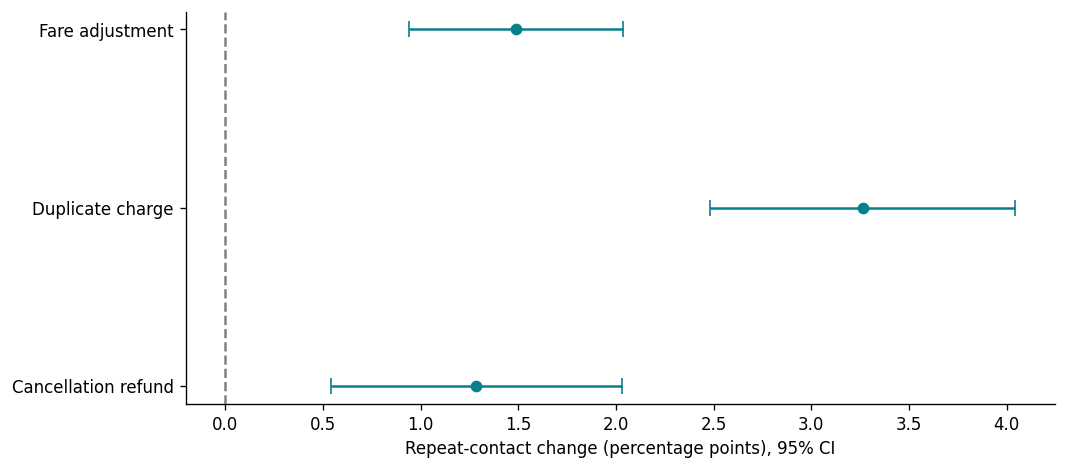

In [4]:
d=segments.filter((pl.col('segment')=='issue_type')&(pl.col('metric')=='repeat_contact_7d')).sort('value')
fig,ax=plt.subplots()
x=d['effect'].to_numpy()*100
ax.errorbar(x,d['value'].to_list(),xerr=np.array([(d['effect']-d['ci_low']).to_numpy()*100,(d['ci_high']-d['effect']).to_numpy()*100]),fmt='o',capsize=5,color='#087f8c')
ax.axvline(0,color='grey',ls='--');ax.set(xlabel='Repeat-contact change (percentage points), 95% CI');plt.tight_layout();plt.show()


## Cost assumptions, not measured savings
Combine refund spend and assumed repeat-contact handling costs per customer. Do not convert elapsed waiting time into agent salary savings. The confidence interval captures sampling uncertainty, not uncertainty in the chosen assumptions.

In [5]:
scenarios=[]
for minutes in [6,12,20]:
    for hourly in [12,18,30]:
        result=scenario(mart,100000,minutes,hourly)
        scenarios.append({k:v for k,v in result.items() if k!='assumption'})
display(pl.DataFrame(scenarios))


volume,repeat_handling_minutes,handling_cost_per_hour,incremental_cost,ci_low,ci_high
i64,i64,i64,f64,f64,f64
100000,6,12,45934.644449,40297.576397,51571.712501
100000,6,18,47114.988386,41454.43297,52775.543802
100000,6,30,49475.676261,43740.045947,55211.306575
100000,12,12,48295.332324,42601.868769,53988.795878
100000,12,18,50656.020198,44869.166891,56442.873505
100000,12,30,55377.395947,49300.273444,61454.51845
100000,20,12,51442.916156,45616.999171,57268.833142
100000,20,18,55377.395947,49300.273444,61454.51845
100000,20,30,63246.355529,56425.707159,70067.003898


## Decision brief
The brief below is generated from the current run. It reports the result, the operational trade-off, the next action and what remains unknown.

In [6]:
display(Markdown((ROOT/'outputs/decision_brief.md').read_text()))

# Support policy decision brief

**Recommendation: Revise and retest.** This is a simulated experiment, not an Uber deployment.

Under the simplified process, seven-day capped time to first resolution decreased from 44.52 hours to 39.29 hours, a decrease of 5.23 hours (95% CI -5.79 hours to -4.68 hours). The rollout target requires the whole 95% interval to sit at or below -2 hours, a reduction of at least 2 hours; this target was met. Customers waited less for a first resolution. This is elapsed customer waiting time, not a measurement of agent labour saved.

Repeat contact increased from 10.02% to 11.99%, an increase of 1.97 percentage points (95% CI +1.58 points to +2.36 points). Its simultaneous one-sided upper bound is +2.388 points against a limit of +1.000 points, so this guardrail failed. Escalation decreased from 5.44% to 5.29%, a decrease of 0.15 percentage points (95% CI -0.43 points to +0.13 points). The interval includes zero, so the direction of the change is not established. Its simultaneous one-sided upper bound is +0.150 points against a limit of +0.500 points, so this guardrail passed. Refund spend per assigned customer increased from $3.69 to $4.13, an increase of $0.44 (95% CI +$0.38 to +$0.49). Its simultaneous one-sided upper bound is +$0.497 against a limit of +$0.500, so this guardrail passed.

The trade-off is repeat contact: a faster first resolution does not settle the full customer problem if more people return. Guardrails that did not establish acceptable harm: repeat_contact_7d. A failed guardrail can mean harm or insufficient precision; inspect its interval before deciding which.

## What I would do next

Keep the current process as the default. Review repeat-contact reasons for duplicate-charge cases, where the simulation deliberately models a harder support problem. Use the segment results to form a follow-up hypothesis, not to claim that differences between segments have been proved. Test a revised explanation or evidence-check step in a fresh customer-randomised experiment before broad rollout.

For an assumed 100,000 future cases, 12 minutes per repeat contact and $18 per handling hour, refund and repeat-contact handling costs rise by $50,656 (95% sampling interval $44,869 to $56,443). These assumptions are editable in the app. The scenario excludes unmeasured changes in initial handling effort, retention and satisfaction value; it is not total profit or ROI.

## Why the comparison is usable

There are 50,180 control and 49,820 treatment customers with a complete seven-day window. Randomisation is per customer, and analysis follows original assignment. The sample-ratio mismatch p-value is 0.255, at or above the 0.001 investigation threshold. The largest absolute baseline standardised difference is 0.008. Each one-to-many table is aggregated before joins, so repeated events cannot multiply refunds.

## What this experiment cannot tell us

Survey response was 49.2% in control and 44.8% in treatment. Satisfaction is measured among respondents and is not a causal estimate for all customers. Outcomes stop at seven days. We have not measured long-run retention, agent congestion, spillovers, actual process adherence or live costs. All patterns were generated from explicit assumptions, and the conclusions apply only to this simulation.


## Handoff
For a real follow-up, agree the guardrail limits with support and finance before launch, inspect repeat-contact reasons, confirm logging and assignment, and test the revised process in new data. Keep the original experiment result intact rather than changing thresholds to make it pass.